# Quasi Montecarlo

---
Nombre: **Alan Jesús Hernández Soto**  
Carrera: **Ingeniería Financiera**  
Materia: **Simulación de Procesos Financieros**  
Tipo de trabajo: **Clase**

---

## 1. Muestreo uniforme

Se generan observaciones aleatorias en el intervalo $[0,1]$. Los histogramas muestran cómo el tamaño de muestra afecta la apariencia de una distribución uniforme.

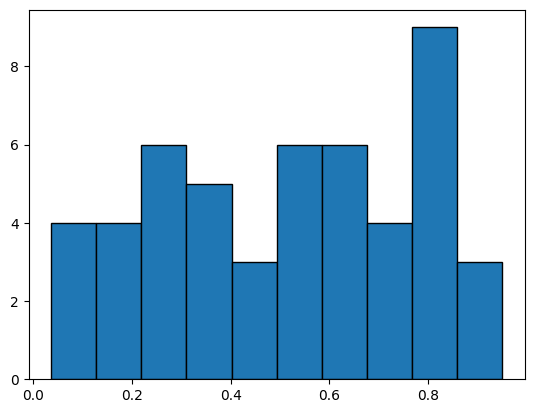

In [128]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(20)
muestras = np.random.uniform(0,1, 50)

plt.hist(muestras, bins=10, edgecolor='black')
plt.show()

El histograma muestra 50 muestras de una distribución uniforme las cuales parecen estar sesgadas y no 'uniformemente' acomadadas.

### Efecto del tamaño de muestra

Se repite el experimento con 100, 500, 1,000 y 1,000,000 de observaciones para apreciar la convergencia visual hacia una distribución uniforme.

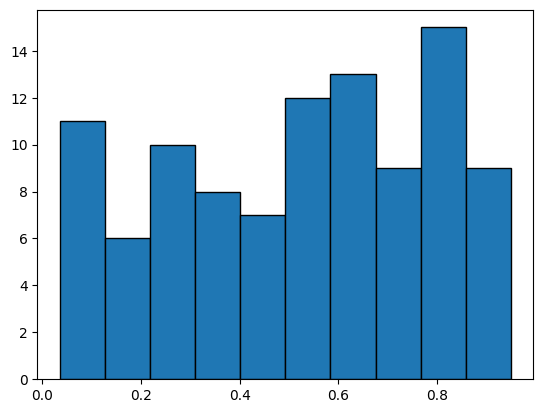

In [129]:
np.random.seed(20)
muestras = np.random.uniform(0,1, 100)

plt.hist(muestras, bins=10, edgecolor='black')
plt.show()

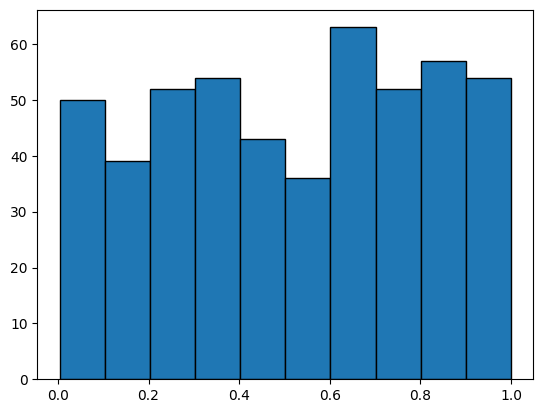

In [130]:
np.random.seed(20)
muestras = np.random.uniform(0,1, 500)

plt.hist(muestras, bins=10, edgecolor='black')
plt.show()

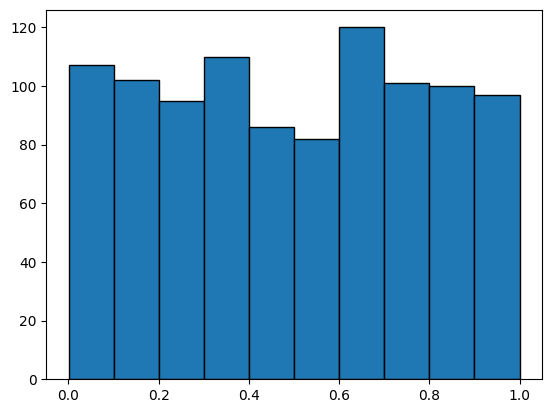

In [131]:
np.random.seed(20)
muestras = np.random.uniform(0,1, 1000)

plt.hist(muestras, bins=10, edgecolor='black')
plt.show()

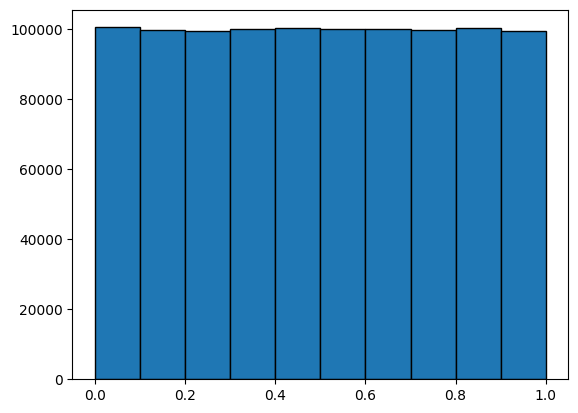

In [132]:
np.random.seed(20)
muestras = np.random.uniform(0,1, 1000000)

plt.hist(muestras, bins=10, edgecolor='black')
plt.show()

La distribucion con 100000 muestras parecen estar mejor distribuidos de manera uniforme pero la frecuencia en cada bin es diferente.

## 2. Integración por Monte Carlo

Se estima la integral $\int_0^1 x^2\,dx = 1/3$ con muestras uniformes. La tabla muestra la estimación y el error absoluto para distintos tamaños de muestra.

In [133]:
np.random.seed(20)
import pandas as pd
def f(x):
    return x**2

m=[]
fu=[]
e=[]
res = pd.DataFrame()
for i in [100, 500, 1000, 5000]:
    x = np.random.uniform(0,1, i)
    y = f(x)
    m.append(i)
    fu.append(y.mean() * (1-0))
    e.append(abs(y.mean() * (1-0) - 1/3))

res['m'] = m
res['f(c) (b-a)'] = fu
res['Error'] = e

res
    

,m,f(c) (b-a),Error
0,100,0.337295,0.003962
1,500,0.349306,0.015973
2,1000,0.322216,0.011118
3,5000,0.342234,0.008900


## 3. Quasi-Monte Carlo con Sobol

La secuencia de Sobol cubre el intervalo de forma más regular que las muestras pseudoaleatorias. Se compara su error con el obtenido mediante Monte Carlo.

In [134]:
from scipy.stats import qmc
sobol = qmc.Sobol(d=1,scramble=True,rng=20)
error_sobol = []
for i in [100, 500, 1000, 5000]:
    u = sobol.random(i)
    y = f(u)
    rest = y.mean() * (1)
    error_sobol.append(abs(rest-1/3))

res['Error qmc'] = error_sobol
res


c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_qmc.py:993: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  sample = self._random(n, workers=workers)


,m,f(c) (b-a),Error,Error qmc
0,100,0.337295,0.003962,0.000444
1,500,0.349306,0.015973,0.000573
2,1000,0.322216,0.011118,0.000180
3,5000,0.342234,0.008900,0.000030


## 4. Estimación de una probabilidad

Se estima $P(X>60)$ para $X\sim N(50,10)$ y se contrastan Monte Carlo tradicional y Quasi-Monte Carlo mediante Sobol transformado a una distribución normal.

In [135]:
from scipy.stats import norm

sobol = qmc.Sobol(d=1,scramble=True,rng=20)
np.random.seed(20)
probability_mc = []
probability_qmc = []
for i in m:
    samples_mc = np.random.normal(50, 10, i)
    samples_sobol = norm.ppf(sobol.random(i), loc=50, scale=10)
    prob_mc = np.mean([samples_mc>60])
    prob_qmc = np.mean([samples_sobol>60])
    probability_mc.append(prob_mc)
    probability_qmc.append(prob_qmc)

results_problem = pd.DataFrame({'m':m, 'MC':probability_mc, 'QMC':probability_qmc})
results_problem



c:\Users\1\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_qmc.py:993: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  sample = self._random(n, workers=workers)


,m,MC,QMC
0,100,0.1700,0.1600
1,500,0.1800,0.1580
2,1000,0.1550,0.1580
3,5000,0.1592,0.1588


---

## 5. Estimación para precio de una Opción
Se usa Sobol con d=252 para devolver un universo con 252 valores e iterar en la matriz dada para el calculo de cada trayectoria. A diferencia del montecarlo tradicional se itera en la matriz de sobol.

In [140]:
S0 = 100
r =0.05
sigma = 0.2
T = 1
n = 252
K = 100

def create_paths_sobol(S0, r, sigma, T, steps, sim):
    sobol = qmc.Sobol(d=252, scramble=True, seed=20)
    dt = T / steps
    paths = np.zeros((steps + 1, sim))
    paths[0, :] = S0
    u = sobol.random(sim)
    z = np.transpose(norm.ppf(u))
    for t in range(steps):
        paths[t+1, :] = paths[t, :] * np.exp((r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt)*z[t, :])
    return paths

paths = create_paths_sobol(S0, r, sigma, T, n, 1024)

# sobol = qmc.Sobol(d=252, scramble=True)
# norm.ppf(sobol.random(), loc=0, scale=1).shape

Gráfica de trayectorias

 ...]

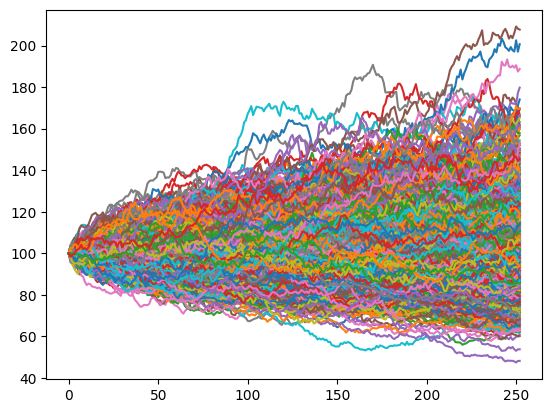

In [141]:
plt.figure()
plt.plot(paths)

Cálculo de precio de una opción call Asíatica y Europea

In [142]:
def pay_off_call_eu(paths, K):
    St = paths[-1,:]
    poff = np.maximum(St-K,0)
    return np.mean(poff)

def pay_off_call_as(paths, K):
    St = np.mean(paths, axis=0)
    poff = np.maximum(St-K,0)
    return np.mean(poff)

expected_eu = pay_off_call_eu(paths, K)
expected_as = pay_off_call_as(paths, K)

expected_eu, expected_as


(np.float64(11.089289822699882), np.float64(6.105639243961377))

## 6. Error de Quasi-Montecarlo con Black-Scholes para Call Europea

Comparación del precio calculado con Black-Scholes y valor estimado con 1024 trayectorias con Quasi-Montecarlo

In [143]:
def bs(S, K, T, r, sigma, call=True):
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    if call:
        price = S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
    else:
        price = K*np.exp(-r*T)*norm.cdf(-d2) - S*norm.cdf(-d1)
    return price

bs = bs(S0, K, T, r, sigma, call=True)

print(f'Error de Quasi Montecarlo con 1024 simulaciones: {abs(bs-expected_eu)}')

Error de Quasi Montecarlo con 1024 simulaciones: 0.6387062505143177
